# Notebook 19: The 720° Turn in Γ: a Γ-Level Synthesis

**Goal:** Restate the famous fact that a spin-½ particle needs a 720° rotation, not 360°, to "come back" entirely in the
language of an indivisible stochastic process, whose only dynamical data are the transition matrices $\Gamma$, and say
exactly which inputs the statement needs.

This notebook is a **synthesis, not a discovery.** Its ingredients are known: interference as indivisibility (Barandes),
indivisibility of two-configuration oscillations (Barandes; Pimenta; Kingman's embedding theorem), projective representations
(Wigner, Bargmann), the homotopy reading of spin (Schulman), the relational observability of the spinor sign (Aharonov and
Susskind) and the 4π neutron experiments (Rauch et al.; Werner et al.). What it adds is a worked, Γ-only assembly for
spin-½, which the ISP papers do not contain (see Prior work).

By the end of this notebook you will be able to:
- Show that an isolated spin's $\Gamma$ is fully restored by a 360° turn
- Show that Stern–Gerlach statistics alone do not require 720°: a classical model reproduces them
- State the one experiment that does (neutron interferometry) as a property of one end-to-end $\Gamma$
- Say when a rotation can and cannot be divisible
- See the end-to-end $\Gamma$ depend only on the homotopy class of the rotation path, and which physical input that needs
- Say precisely what ISP explains here and what it only relocates

---
> ### 📓 Annotated study copy
>
> Study copy of `19_spinors_as_memory.ipynb`. Same code and outputs, plus sections marked **📖 In depth**, **🔍 Reading the code** and **🔭 Looking ahead**.
>
> Written 2026-11-16 from the clean notebook, `isp/spinor.py` and `notes/lit-spinor-4pi-2026-11-16.md`. The question: *a spin-½ particle famously needs a 720° turn to come back.
> What does that look like when the only dynamical data are the transition matrices Γ of an indivisible stochastic process?*
> Short answer: an isolated spin's Γ comes back after 360°. The 720° appears only in an interferometer, relative to an unrotated arm, as a property of one end-to-end Γ
> that no divisible description reproduces. It also needs a physical input (the field adds no spin-independent phase that grows with the turn) that Γ alone cannot supply.
>
> **A synthesis, not a discovery.** Every ingredient is known: interference as indivisibility (Barandes), indivisibility of two-configuration oscillations
> (Barandes; Pimenta; Kingman), projective representations (Wigner, Bargmann), the homotopy reading of spin (Schulman), the relational sign (Aharonov and Susskind)
> and the 4π neutron experiments (Rauch et al.; Werner et al.). What the notebook adds is a worked, Γ-only assembly for spin-½. No such treatment was found in the ISP
> literature as of November 2026; that is a statement about a search, not a claim of a new result.
>
> **Audit (2026-11-16).** Two independent audits (correctness; novelty and attribution) moved several claims to "known", corrected the divisibility statement (turns of
> at most 90° do have a divisible description) and found that the 720° needs the determinant-1 input of section 5. This version says so.
---

### 📖 In depth: what Γ explains about the 720° turn, and what it doesn't

**What Γ shows**
- **A lone spin forgets every full turn.** Its Γ is restored by 360°, and the sign of the law Θ is invisible to $|\Theta|^2$ (section 1).
- **Where the 720° lives.** In one end-to-end Γ of a two-path interferometer, relative to the unrotated arm (section 3).
- **Why it needs indivisibility.** Divide the process at the beam splitters and every turning angle reads ½ (section 3). A rotation that moves the configurations and then comes back cannot be divisible at all (section 4, a known result).
- **The two-valued dependence on the rotation path.** On closed rotation histories (the rotation the field applies to the spin returns to the identity) the end-to-end Γ takes exactly two values, one per class of $\pi_1(SO(3)) = \mathbb{Z}_2$ (section 6).

**What Γ does not supply**
- **The $\cos^2(\theta/2)$ law.** It comes from the law Θ, as in standard quantum theory (section 7).
- **The determinant-1 input.** A phase-shifted law gives the lone spin exactly the same Γ and has period 360° (section 5). Choosing between them is physics, not a consequence of Γ.
- **A unique explanation.** A model with enough hidden configurations can carry an SU(2) action classically (section 7's escape hatch).

**Net.** ISP restates the 720° fact as a property of an end-to-end Γ and shows that the property needs indivisibility. It does not derive the fact: the derivation still runs through the law Θ and one physical input.

<!-- expansion:19:before-you-start -->
### 🧭 Before you start

**What this notebook is for.** Every quantum mechanics course says a spin-½ particle needs a 720° turn to return to its starting state. This notebook restates that fact in
Barandes's picture, where a system always occupies one definite configuration and moves between configurations with *indivisible* transition probabilities Γ. It finds where
in Γ the 720° can be seen (only in an interferometer), why seeing it needs indivisibility, and which physical input it rests on. It is a synthesis of known results; the 📚 and 🧮
cells show where each piece comes from.

**Prerequisites.**
- Griffiths ch. 4 on spin-½: Pauli matrices, spinors, and the rotation operator $e^{-i\varphi\,\hat n\cdot\vec\sigma/2}$.
- Notebooks 02–03: divisible and indivisible transition matrices.
- Notebook 05: interference as the indivisibility defect. Notebook 06: division events.
- No group theory or topology beyond Griffiths. The 📖 and 🧮 cells explain projective representations and $\pi_1(SO(3))$ from scratch.

**How to run it.** From the `notebooks/` folder, *Kernel > Restart & Run All*, or step through with Shift+Enter. The first code cell adds the folder one level up to `sys.path`
and imports from `isp/spinor.py`, so `isp/` must sit next to `notebooks/`. It needs numpy, scipy and matplotlib. The whole notebook runs in about ten seconds.


<!-- expansion:19:glossary -->
### 📘 Glossary

- **Configuration.** What the system is actually in. For the lone spin, $\uparrow_z$ or $\downarrow_z$. In the interferometer, an (arm, spin) pair: four configurations.
- **Γ (transition matrix).** $\Gamma_{ij}(t\leftarrow 0)$ = probability of configuration $i$ at $t$, given $j$ at 0. Each column sums to 1.
- **Θ (the law).** A complex matrix with $\Gamma = |\Theta|^2$ entry by entry. Here a 2×2 (lone spin) or 4×4 (interferometer) unitary.
- **Divisible; division event.** Γ is divisible at $t'$ if $\Gamma(t\leftarrow 0) = \Gamma(t\leftarrow t')\,\Gamma(t'\leftarrow 0)$ with $\Gamma(t\leftarrow t')$ a genuine stochastic matrix. A division event is a time at which the
  process divides, for example because something recorded the configuration.
- **Indivisible.** Not divisible at some intermediate times. Interference is its signature.
- **End-to-end Γ.** The transition matrix from the source to the detectors, with no division in between.
- **Permutation matrix.** A stochastic matrix of 0s and 1s with one 1 in each row and column: a deterministic relabelling of configurations.
- **SO(3).** The rotations of space, as 3×3 matrices. A 360° turn is the identity.
- **SU(2).** The 2×2 unitary matrices with determinant 1. Each rotation corresponds to two of them, $\pm\Theta$: SU(2) is the **double cover** of SO(3).
- **Projective representation.** A law that respects composition only up to a phase: $\Theta(R_1)\Theta(R_2) = e^{i\alpha}\,\Theta(R_1R_2)$.
- **Determinant-1 law.** A law with $\det\Theta = 1$, as generated by a traceless coupling such as $-\vec\mu\cdot\vec B$.
- **Homotopy class; $\pi_1$.** Closed loops that can be deformed into each other form one class. $\pi_1(SO(3)) = \mathbb{Z}_2$ says there are exactly two classes.
- **Schur–Hadamard gauge.** Barandes's name for multiplying each entry of Θ by its own phase, which leaves Γ unchanged.
- **Papers 1–3.** Barandes, "The Stochastic-Quantum Correspondence" (arXiv:2302.10778), "The Stochastic-Quantum Theorem" (arXiv:2309.03085), "Quantum Systems as Indivisible
  Stochastic Processes" (arXiv:2507.21192). Page numbers in the 📚 cells are those of the PDFs in `papers to study/`.


In [1]:
#import a bunch of python libraries
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from isp.spinor import (su2, so3, so3_of, gamma, law_from_path, rotation_vector, axis_loop, belt_family, concat, random_loop,
                        total_turning, detector_probs, divisible_detector_probs, kochen_specker_up_prob, is_permutation)

### 📖 In depth: the idea in plain words

- **The famous fact.** Turn a spin-½ particle's quantum state through 360° and it picks up a minus sign. Only a 720° turn brings it back exactly.
- **The catch.** A minus sign on the whole state changes no probability. Barandes's picture works with probabilities: the spin *is* up or down, and Γ says how likely it is to
  move from one to the other. By that measure one full turn puts everything back.
- **Where the sign shows up.** Split a neutron beam in two, turn the spins in one path only, and bring the paths back together. Now the sign is relative to the other path, and it
  decides which detector fires. A 360° turn sends every neutron to the *other* detector.
- **What that takes.** The two paths must not be settled midway. If anything recorded which path each neutron took, each detector would get half of them, whatever the turn.
- **For a search engineer.** A score built from a squared similarity, $|\langle q, v\rangle|^2$, cannot tell a vector $v$ from $-v$. Add two vectors before scoring (say, a centroid of
  two passage embeddings) and the sign decides whether they reinforce or cancel. The lone spin is the squared score; the interferometer is the sum.

## 1. A Lone Spin Forgets Every Full Turn

Take the spin's configurations to be $\{\uparrow_z, \downarrow_z\}$, the two outcomes of a Stern–Gerlach magnet along $z$
(Griffiths §4.4). A field that turns the spin by angle $\varphi$ about an axis $\hat n$ gives the law
$\Theta = e^{-i\varphi\,\hat n\cdot\vec\sigma/2}$ and the transition matrix $\Gamma = |\Theta|^2$ (entrywise).

The textbook statement is that $\Theta(2\pi) = -I$: "the spinor changes sign". We ask what $\Gamma$ says.

In [2]:
z, y = [0, 0, 1], [0, 1, 0]
for name, ax in [("z", z), ("y", y), ("tilted (1,2,3)", [1, 2, 3])]:
    for deg in [180, 360, 720]:
        Th = su2(ax, np.radians(deg))
        print(f"axis {name:14s} {deg:3d}°:  Θ diag = {np.round(np.diag(Th), 3)},  Γ = {np.round(gamma(Th), 3).tolist()}")

U = su2([1, -1, 2], 1.3)
print("\nΓ(Θ) == Γ(−Θ):", np.allclose(gamma(U), gamma(-U)), "   same physical rotation R:", np.allclose(so3_of(U), so3_of(-U)))

axis z              180°:  Θ diag = [0.-1.j 0.+1.j],  Γ = [[1.0, 0.0], [0.0, 1.0]]
axis z              360°:  Θ diag = [-1.-0.j -1.+0.j],  Γ = [[1.0, 0.0], [0.0, 1.0]]
axis z              720°:  Θ diag = [1.+0.j 1.-0.j],  Γ = [[1.0, 0.0], [0.0, 1.0]]
axis y              180°:  Θ diag = [0.+0.j 0.+0.j],  Γ = [[0.0, 1.0], [1.0, 0.0]]
axis y              360°:  Θ diag = [-1.+0.j -1.+0.j],  Γ = [[1.0, 0.0], [0.0, 1.0]]
axis y              720°:  Θ diag = [1.+0.j 1.+0.j],  Γ = [[1.0, 0.0], [0.0, 1.0]]
axis tilted (1,2,3) 180°:  Θ diag = [0.-0.802j 0.+0.802j],  Γ = [[0.643, 0.357], [0.357, 0.643]]
axis tilted (1,2,3) 360°:  Θ diag = [-1.-0.j -1.+0.j],  Γ = [[1.0, 0.0], [0.0, 1.0]]
axis tilted (1,2,3) 720°:  Θ diag = [1.+0.j 1.-0.j],  Γ = [[1.0, 0.0], [0.0, 1.0]]

Γ(Θ) == Γ(−Θ): True    same physical rotation R: True


- **About $z$**, $\Gamma$ is the identity at every angle. The configurations $\uparrow_z,\downarrow_z$ never change, and
  nothing in $\Gamma$ records whether the turn was 0°, 360° or 720°.
- **About any axis**, $\Gamma$ returns to the identity at 360°. The y-rotation gives
  $\Gamma = \begin{pmatrix}\cos^2\frac\theta2 & \sin^2\frac\theta2\\ \sin^2\frac\theta2 & \cos^2\frac\theta2\end{pmatrix}$,
  which has period $2\pi$.
- **For the isolated spin the sign is gauge.** $\Theta$ and $-\Theta$ give the same $\Gamma$. This is the uniform special case of
  Barandes's Schur–Hadamard gauge freedom (phases on individual entries of $\Theta$). Section 3 shows that the sign is *not*
  gauge once the spin is one branch of a larger process.

### 📖 In depth: configurations, Γ and Θ, and why $|\Theta|^2$ kills the sign

- **Configurations** are what the system actually is in at each moment. Here: $\uparrow_z$ or $\downarrow_z$, the two ways a $z$-oriented Stern–Gerlach magnet can deflect the particle.
  In Barandes's picture the spin always occupies one of them; it is never "in between".
- **Γ** is the dynamics: $\Gamma_{ij}(t\leftarrow 0)$ is the probability of configuration $i$ at time $t$, given $j$ at time 0. Each column sums to 1. In an *indivisible* process that is all there is:
  generically, for some pairs of times, there is no stochastic matrix $\Gamma(t\leftarrow t')$ between them to chain together.
- **Θ** is a complex matrix with $\Gamma_{ij} = |\Theta_{ij}|^2$. Here it is the familiar rotation operator $e^{-i\varphi\,\hat n\cdot\vec\sigma/2}$ (Griffiths §4.4). Θ composes, $\Theta(t\leftarrow 0) = \Theta(t\leftarrow t')\,\Theta(t'\leftarrow 0)$,
  but squaring entry by entry destroys the composition, because the cross terms that a product of Θs contains are lost. Barandes compares Θ to a potential for Γ: useful for building Γ, not itself a probability.
- **Why the sign dies.** $|{-\Theta_{ij}}|^2 = |\Theta_{ij}|^2$, entry by entry. So the 360° law $\Theta = -I$ and the 0° law $\Theta = I$ give the same $\Gamma = I$. More generally, multiplying each entry
  of Θ by its own phase leaves Γ alone (Barandes's Schur–Hadamard gauge freedom); the overall minus sign is the case where every phase is $\pi$.
- **Reading the tilted-axis line.** For a turn $\varphi$ about a unit axis $\hat n$, $\Gamma_{\uparrow\uparrow} = \cos^2(\varphi/2) + n_z^2\sin^2(\varphi/2)$. For $\hat n \propto (1,2,3)$ and $\varphi = 180°$ this is
  $n_z^2 = 9/14 = 0.643$, the number printed above. At 360° the sine vanishes and $\Gamma = I$ for every axis.

In [3]:
s = np.linspace(0, 1, 9)
hist_360 = [gamma(su2(z, 2 * np.pi * t)) for t in s]
hist_720 = [gamma(su2(z, 4 * np.pi * t)) for t in s]
print("Whole Γ(s←0) history, 360° vs 720° turn about z, identical at every s:",
      all(np.allclose(a, b) for a, b in zip(hist_360, hist_720)))

Whole Γ(s←0) history, 360° vs 720° turn about z, identical at every s: True


Even the entire history of the isolated spin's $\Gamma$, not just its endpoint, is the same for a 360° and a 720° turn
about $z$.

<!-- expansion:19:recap-1 -->
### 📝 Recap: section 1

- The lone spin has two configurations. Its Γ is $|\Theta|^2$, with Θ the textbook rotation operator.
- About $z$, $\Gamma = I$ at every angle. About any axis, Γ has period 360°.
- Θ and −Θ give the same Γ, so for the lone spin the sign at 360° is gauge.
- Not only the endpoint: the whole history $\Gamma(s\leftarrow 0)$ of a 360° turn and of a 720° turn about $z$ is the same.


## 2. Stern–Gerlach Alone Does Not Need 720°

Griffiths's sequential Stern–Gerlach measurements give $P(\uparrow_{\hat a}\mid\uparrow_{\hat p}) = \cos^2(\theta/2)$ for analyzers
at relative angle $\theta$. The half-angle looks spinorial, but it is not evidence for 720°. Kochen and Specker (1967, §6)
gave a classical model: the hidden configuration is a unit vector $\lambda$ drawn on the hemisphere around $\hat p$ with density
$\propto \lambda\cdot\hat p$, and the outcome along $\hat a$ is up iff $\lambda\cdot\hat a > 0$.

### 📖 In depth: the Kochen–Specker model, intuitively

- **The hidden configuration** is an arrow $\lambda$, an ordinary unit vector. Preparing "up along $\hat p$" draws $\lambda$ somewhere in the hemisphere around $\hat p$, more often near $\hat p$:
  the density is proportional to $\cos$ of the angle between $\lambda$ and $\hat p$.
- **A measurement along $\hat a$** reports "up" exactly when $\lambda$ points into $\hat a$'s hemisphere, $\lambda\cdot\hat a > 0$. Given $\lambda$, the outcome is certain; the probability comes only
  from not knowing $\lambda$.
- **A rotation** turns $\lambda$ like any arrow. A 360° turn returns every arrow exactly to where it was. There are no signs anywhere in the model.
- **The result** is exactly $\cos^2(\theta/2)$ for analyzers at angle $\theta$ (the 🧮 cell below shows why, with one picture). So the half-angle in the sequential Stern–Gerlach formula is,
  on its own, no evidence of a 720° period.
- **What the model is not.** It is a model of one spin and one measurement at a time. The notebook uses it only to show that single-spin statistics cannot force 720°; it says nothing
  about correlated pairs of spins.

max |KS − cos²(θ/2)| = 0.0022  (Monte Carlo, 2×10⁵ samples)


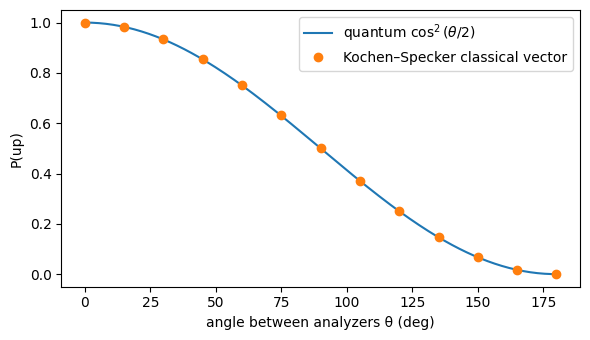

In [4]:
th = np.linspace(0, np.pi, 13)
ks = [kochen_specker_up_prob(t) for t in th]
print("max |KS − cos²(θ/2)| =", f"{max(abs(k - np.cos(t/2)**2) for k, t in zip(ks, th)):.4f}  (Monte Carlo, 2×10⁵ samples)")

fig, ax = plt.subplots(figsize=(6, 3.5))
tt = np.linspace(0, np.pi, 200)
ax.plot(np.degrees(tt), np.cos(tt / 2) ** 2, label=r'quantum $\cos^2(\theta/2)$')
ax.plot(np.degrees(th), ks, 'o', label='Kochen–Specker classical vector')
ax.set_xlabel('angle between analyzers θ (deg)'); ax.set_ylabel('P(up)'); ax.legend(); plt.tight_layout(); plt.show()

In this model a rotation is an SO(3) action on a classical vector, and a 360° turn restores every hidden configuration
exactly. Single-spin Stern–Gerlach statistics are therefore compatible with plain 360° periodicity, and no framework, ISP
or otherwise, can derive 720° from them alone.

<!-- expansion:19:derive-kochen-specker -->
### 🧮 Worked derivation: the Kochen–Specker model gives $\cos^2(\theta/2)$

Put $\hat p$ along $z$ and $\hat a = (\sin\theta, 0, \cos\theta)$, with $\theta \le 90°$ for now.

1. **Project onto the disk.** A small patch of the hemisphere at angle α from $z$ projects onto the equatorial disk with its area multiplied by $\cos\alpha$. So a density proportional to
   $\cos\alpha$ on the hemisphere is exactly a *uniform* density on the unit disk underneath. (That is how `kochen_specker_up_prob` samples: radius $\sqrt u$, uniform angle.)
2. **Find the "down" region.** The outcome is down when $\lambda\cdot\hat a < 0$. The boundary $\lambda\cdot\hat a = 0$ is a great circle tilted by θ, and its upper half projects to half an ellipse
   with semi-axes 1 and $\cos\theta$. The down region projects to the part of the half-disk on the $-x$ side that lies outside this half-ellipse.
3. **Compare areas.** Half-disk $\pi/2$, half-ellipse $\tfrac\pi2\cos\theta$, whole disk π. So

$$P(\text{down}) = \frac{\tfrac\pi2(1 - \cos\theta)}{\pi} = \sin^2\frac\theta2, \qquad P(\text{up}) = \cos^2\frac\theta2 .$$

For θ > 90° the ellipse sits on the other side and the same count gives the same formula.

Check: θ = 60°, 90°, 120° give 0.75, 0.5, 0.25. A run of `kochen_specker_up_prob` with $2\times10^6$ samples gives 0.7497, 0.4997, 0.2496.


<!-- expansion:19:recap-2 -->
### 📝 Recap: section 2

- Sequential Stern–Gerlach gives $\cos^2(\theta/2)$, and the half-angle looks spinorial.
- A classical arrow model (Kochen and Specker 1967, §6) reproduces it exactly, and in that model a 360° turn restores everything.
- So no framework can get 720° out of single-spin statistics alone. The next section needs two paths.


## 3. The Experiment That Does: a Two-Path Interferometer in Γ

Rauch et al. and Werner et al. (1975) split a neutron beam, turned the spin in one arm by a field, recombined the beams and
watched the count rate as the turning angle $\varphi$ varied. In ISP terms:

- **Configurations:** (arm, spin) with arm $\in\{A, B\}$: four configurations.
- **Law:** beam splitter, a spin turn in arm A only, beam splitter. The two outputs are detectors O and H.
- **Data:** the end-to-end $\Gamma$, from source to detector, as a function of $\varphi$. It is computed here from the law
  $\Theta$, but every statement below is about $\Gamma$.
- **Labels.** One binary index does three jobs: the input port before the first splitter, the arm (A = 0, B = 1) between
  the splitters, and the detector (O = 0, H = 1) after the second splitter.

<!-- expansion:19:books-interference -->
### 📚 From the papers: interference is indivisibility

- **Paper 1, §3.5 "Interference", pp. 13–14.** For a unistochastic Γ, Barandes defines a relative law $U(t\leftarrow t') = U(t\leftarrow 0)\,U^\dagger(t'\leftarrow 0)$ (eq. (39)) and notes that "this composition law does
  not extend to the transition matrix Γ(t ← 0) due to cross terms" (p. 14).
- **p. 14,** after writing the difference between $\Gamma(t\leftarrow 0)$ and the would-be division $\Gamma(t\leftarrow t')\Gamma(t'\leftarrow 0)$ as a sum of cross terms (eq. (43)): "Remarkably, the right-hand side of
  (43) gives the general mathematical formula for quantum interference, despite the absence of manifestly quantum-theoretic assumptions." And: "interference is nothing more than a
  generic discrepancy between the actual indivisible stochastic dynamics and a heuristic-approximate divisible stochastic dynamics."
- **§3.7, p. 19,** on a system watched by its environment: its transition matrix becomes one "that is manifestly divisible at t′", and "It is therefore natural to refer to the new
  conditioning time t′ as a division event."

**What follows for this section.** The interferometer's end-to-end Γ is the "actual indivisible" dynamics. The dashed curve, divided at the splitters, is the "heuristic-approximate
divisible" one. The 720° signal is exactly the discrepancy between them.


<!-- expansion:19:derive-beam-splitter -->
### 🧮 Worked derivation: the beam-splitter arithmetic for $P(O) = \cos^2(\varphi/4)$

Follow amplitudes on the arm, carrying the spin state χ along. The particle enters through input port 0.

1. **First splitter:** $\tfrac{1}{\sqrt2}\,|A\rangle\chi + \tfrac{1}{\sqrt2}\,|B\rangle\chi$.
2. **Arm A turns the spin:** $\tfrac{1}{\sqrt2}\,|A\rangle\,\Theta_A\chi + \tfrac{1}{\sqrt2}\,|B\rangle\chi$.
3. **Second splitter:** $|A\rangle \to (|O\rangle + |H\rangle)/\sqrt2$ and $|B\rangle \to (|O\rangle - |H\rangle)/\sqrt2$. Collecting terms,

$$|O\rangle\,\tfrac12(\Theta_A + I)\chi \;+\; |H\rangle\,\tfrac12(\Theta_A - I)\chi .$$

   `interferometer_law` has exactly these two 2×2 blocks (checked numerically).
4. **Probability of O, summed over the spin:**

$$P(O) = \tfrac14\,\|(\Theta_A + I)\chi\|^2 = \tfrac12\bigl(1 + \mathrm{Re}\,\langle\chi|\Theta_A|\chi\rangle\bigr).$$

5. **Insert the rotation.** $\Theta_A = \cos\frac\varphi2\,I - i\sin\frac\varphi2\,\hat n\cdot\vec\sigma$. The expectation $\langle\chi|\hat n\cdot\vec\sigma|\chi\rangle$ is real (the σ's are Hermitian), so after the factor $-i$ it adds
   nothing to the real part: $\mathrm{Re}\,\langle\chi|\Theta_A|\chi\rangle = \cos\frac\varphi2$ for every axis and every χ. Hence

$$P(O) = \tfrac12\Bigl(1 + \cos\frac\varphi2\Bigr) = \cos^2\frac\varphi4 .$$

At φ = 0°, 180°, 360°, 540°, 720° this is 1, ½, 0, ½, 1, the table below. At 360°, $\Theta_A = -I$ and the two arms cancel at O. The sign that arm A's own Γ could not see (section 1)
is now a *relative* sign between two arms that meet. Since the answer is the same for spin up and spin down, it holds for any mixture too (checked: 200 random axes, angles and
spin mixtures agree with $\cos^2(\varphi/4)$ to $10^{-15}$).


φ =   0°:  P(O) = 1.000   P(H) = 0.000   (cos²(φ/4) = 1.000)
φ = 180°:  P(O) = 0.500   P(H) = 0.500   (cos²(φ/4) = 0.500)
φ = 360°:  P(O) = 0.000   P(H) = 1.000   (cos²(φ/4) = 0.000)
φ = 540°:  P(O) = 0.500   P(H) = 0.500   (cos²(φ/4) = 0.500)
φ = 720°:  P(O) = 1.000   P(H) = 0.000   (cos²(φ/4) = 1.000)


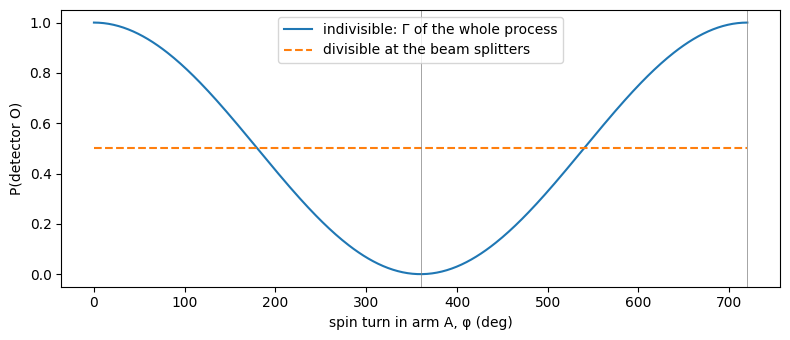

In [5]:
phis = np.linspace(0, 4 * np.pi, 401)
PO = [detector_probs(su2(z, p))["O"] for p in phis]
PO_div = [divisible_detector_probs(gamma(su2(z, p)))["O"] for p in phis]
for deg in [0, 180, 360, 540, 720]:
    p = detector_probs(su2(z, np.radians(deg)))
    print(f"φ = {deg:3d}°:  P(O) = {p['O']:.3f}   P(H) = {p['H']:.3f}   (cos²(φ/4) = {np.cos(np.radians(deg)/4)**2:.3f})")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.degrees(phis), PO, label='indivisible: Γ of the whole process')
ax.plot(np.degrees(phis), PO_div, '--', label='divisible at the beam splitters')
for v in (360, 720): ax.axvline(v, color='gray', lw=0.5)
ax.set_xlabel('spin turn in arm A, φ (deg)'); ax.set_ylabel('P(detector O)'); ax.legend(); plt.tight_layout(); plt.show()

- **The period is 720°.** $P(O) = \cos^2(\varphi/4)$: a 360° turn sends every particle to the *other* detector, and only a
  720° turn restores the original pattern. The same holds for any rotation axis and any incoming spin distribution, because
  $P(O) = \tfrac12\bigl(1 + \mathrm{Re}\,\langle\chi|\Theta_A|\chi\rangle\bigr)$ and $\mathrm{Re}\,\langle\chi|\Theta_A|\chi\rangle = \cos(\varphi/2)$
  for every axis and every spin state $\chi$.
- **It is relational.** The 360° turn is invisible in arm A's own $\Gamma$ (section 1). It becomes visible only relative to
  the unrotated arm B, which is Aharonov and Susskind's (1967) point about the observability of the spinor sign.
- **Like all interference, it requires indivisibility.** If the process divided at the beam splitters, each stage would
  contribute its own $\Gamma$: the balanced splitter's $\Gamma$ is all ½, so the detector probability is ½ whatever happens in
  between (dashed line), even at $\varphi = 0$. That interference is a signature of indivisibility, and that division events
  erase it, is Barandes's (2302.10778 §§3.5, 3.7).

### 🔍 Reading the code: the interferometer in `isp/spinor.py`

- **Configurations.** Index $2\cdot\text{arm} + \text{spin}$: 0 = (A, ↑), 1 = (A, ↓), 2 = (B, ↑), 3 = (B, ↓). After the second splitter, arm index 0 is detector O and 1 is detector H.
- **`BS`** $= \tfrac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ acts on the arm index; `np.kron(BS, I2)` leaves the spin alone.
- **`interferometer_law(Θ_A)`** is $S\,(P_A\otimes\Theta_A + P_B\otimes I)\,S$ with $S$ = `kron(BS, I2)`: split, turn the spin in arm A only, recombine. A 4×4 unitary.
- **`detector_probs`** takes $\Gamma = |\cdot|^2$ of that whole 4×4 law, applies it to a starting distribution on configurations 0 and 1 (the particle enters through input port 0 with the
  given spin distribution), and adds configurations 0+1 for O and 2+3 for H. It uses nothing but the end-to-end Γ.
- **`divisible_detector_probs`** is the same experiment with a division event at each splitter: each stage is replaced by its own Γ and the three Γs are multiplied,
  $|S|^2\,(P_A\otimes\Gamma_A + P_B\otimes I)\,|S|^2$. That is the dashed line.

<!-- expansion:19:derive-divided -->
### 🧮 Worked derivation: why dividing at the splitters gives ½

Replace each stage by its own Γ and multiply.
- The splitter's Γ is $|BS|^2 = \begin{pmatrix}\frac12&\frac12\\ \frac12&\frac12\end{pmatrix}$: from either input, each output with probability ½.
- After the first splitter: arm A or arm B, probability ½ each, spin unchanged.
- In the arms: arm A's spin moves according to $\Gamma_A$, arm B's stays put. Neither changes the arm.
- After the second splitter: from *either* arm, detector O with probability ½, whatever the spin. So $P(O) = \tfrac12\cdot\tfrac12 + \tfrac12\cdot\tfrac12 = \tfrac12$.

The turning angle never enters. Even at φ = 0, where the real interferometer sends every particle to O, the divided version gives ½. Dividing throws away the cross terms of step 4
above, which carry all the dependence on φ. (Checked: `divisible_detector_probs` returns 0.5 to machine precision for 50 random turns and spin mixtures.)


<!-- expansion:19:recap-3 -->
### 📝 Recap: section 3

- Four configurations, (arm, spin). The data: one end-to-end Γ from source to detectors, as a function of φ.
- $P(O) = \cos^2(\varphi/4)$: period 720°, for any axis and any spin input.
- The 360° sign is relational: invisible in arm A's own Γ, visible against the unrotated arm B (Aharonov and Susskind's point).
- Divided at the splitters, every φ gives ½. The 720° effect is interference, so it needs indivisibility (Barandes, Paper 1 §§3.5, 3.7).


## 4. A Rotation That Moves the Configurations and Comes Back Cannot Be Divisible

Can the turn inside arm A be divisible on its own? Partly.

**Short turns can be.** For the y-rotation, $\Gamma(t)\Gamma(s)^{-1}$ is stochastic exactly when $|\cos t| \le |\cos s|$. So
any turn of at most 90° has a divisible description: a time-dependent flip rate $r(\theta) = \tfrac12\tan\theta$ reproduces
$\Gamma_y$ exactly. Equivalently, $\Gamma_y(\theta) = e^{L\tau}$ with $L = (X - I)/2$ and $\tau = -\ln\cos\theta$. Divisibility
over every pair of times fails once the turn passes 90°, where $\det\Gamma = \cos\theta$ goes negative.

**A turn that moves the configurations and returns cannot be.** (A turn about $z$ never moves them: its $\Gamma = I$ at
every angle, which is trivially divisible.) Suppose a divisible family, homogeneous or not, ever returns to the identity:
$\Gamma(T\leftarrow 0) = I$. Then each $\Gamma(t\leftarrow 0)$ has the stochastic inverse $\Gamma(T\leftarrow t)$. A stochastic
matrix with a stochastic inverse is a permutation, and a continuous family of permutations starting at $I$ is constant.
Any rotation that turns configurations into one another and then comes back must therefore be indivisible.

<!-- expansion:19:derive-criterion -->
### 🧮 Worked derivation: when is $\Gamma_y(t)\,\Gamma_y(s)^{-1}$ stochastic?

The y-rotation gives $\Gamma_y(\theta) = \begin{pmatrix}\cos^2\frac\theta2 & \sin^2\frac\theta2\\ \sin^2\frac\theta2 & \cos^2\frac\theta2\end{pmatrix}$. Below, $s$ and $t$ are two turning angles.

1. **Eigenvectors.** Any matrix $\begin{pmatrix}a&b\\b&a\end{pmatrix}$ has eigenvector (1, 1) with eigenvalue $a + b$ and (1, −1) with eigenvalue $a - b$. For $\Gamma_y$ these are 1 and
   $\cos^2\frac\theta2 - \sin^2\frac\theta2 = \cos\theta$, so $\det\Gamma_y(\theta) = \cos\theta$.
2. **The would-be middle step.** All these matrices share the eigenvectors, so $M = \Gamma_y(t)\Gamma_y(s)^{-1}$ has eigenvalues 1 and $r = \cos t/\cos s$ and the same symmetric form:
   $M = \begin{pmatrix}\frac{1+r}2 & \frac{1-r}2\\ \frac{1-r}2 & \frac{1+r}2\end{pmatrix}$.
3. **Stochastic?** The columns already sum to 1. The entries are non-negative exactly when $-1 \le r \le 1$, that is $|\cos t| \le |\cos s|$.
   Against the printed table: s = 1.0, t = 2.0 gives r = −0.770 and smallest entry $(1 + r)/2 = +0.115$ (stochastic); s = 1.5, t = 2.0 gives r = −5.88 and −2.441 (not);
   s = 2.5, t = 3.0 gives r = +1.236 and an off-diagonal entry of −0.118 (not).
4. **A divisible description up to 90°.** For $0 \le s \le t < 90°$, $\cos$ is decreasing and positive, so every pair passes. For a small step, $r = \cos(\theta + d\theta)/\cos\theta \approx 1 - \tan\theta\,d\theta$,
   and the off-diagonal entry $(1 - r)/2 = \tfrac12\tan\theta\,d\theta$: a flip rate $\tfrac12\tan\theta$. On the clock $\tau = -\ln\cos\theta$ that is a constant-rate process $e^{L\tau}$ with $L = (X - I)/2$, whose
   eigenvalue $-1$ on (1, −1) gives $e^{-\tau} = \cos\theta$. The clock runs to infinity at 90° (τ = 0.69 at 60°, 4.05 at 89°), where $\Gamma_y$ is all ½ and its determinant is 0.
5. **Past 90°.** Now $\cos\theta < 0$, and pairs with $s < 90° < t$ and $|\cos t| > |\cos s|$ fail (take $s$ just below 90°, where $\cos s \approx 0$). No divisible description covers the whole of a turn that goes past 90°.


In [6]:
G = lambda t: gamma(su2(y, t))
mid = lambda t, s: G(t) @ np.linalg.inv(G(s))
print("Γ(t)Γ(s)⁻¹ stochastic?   (predicted: |cos t| ≤ |cos s|)")
for s_, t_ in [(0.6, 1.4), (1.0, 2.0), (1.5, 2.0), (2.5, 3.0)]:
    M = mid(t_, s_)
    print(f"  s = {s_}, t = {t_}:  min entry {M.min():+.3f}   stochastic: {M.min() > -1e-12}   predicted: {abs(np.cos(t_)) <= abs(np.cos(s_))}")

th_ = np.linspace(0, 1.5, 7)
L = np.array([[-0.5, 0.5], [0.5, -0.5]])
print("\nmax |e^{L(−ln cos θ)} − Γ_y(θ)| for θ ≤ 1.5:", f"{max(np.abs(expm(L * -np.log(np.cos(t))) - G(t)).max() for t in th_):.1e}")

rng = np.random.default_rng(1)
A = rng.random((3, 3)); np.fill_diagonal(A, 0); Lr = A - np.diag(A.sum(0))
print("Random Markov generator, e^{Lt} a permutation for t in {0.5, 2, 8}?", [is_permutation(expm(Lr * t)) for t in (0.5, 2, 8)])

Γ(t)Γ(s)⁻¹ stochastic?   (predicted: |cos t| ≤ |cos s|)
  s = 0.6, t = 1.4:  min entry +0.397   stochastic: True   predicted: True
  s = 1.0, t = 2.0:  min entry +0.115   stochastic: True   predicted: True
  s = 1.5, t = 2.0:  min entry -2.441   stochastic: False   predicted: False
  s = 2.5, t = 3.0:  min entry -0.118   stochastic: False   predicted: False

max |e^{L(−ln cos θ)} − Γ_y(θ)| for θ ≤ 1.5: 6.7e-16
Random Markov generator, e^{Lt} a permutation for t in {0.5, 2, 8}? [False, False, False]


All of this is known. Barandes's own first example of an indivisible process is this $\Gamma$ with $f = \cos^2\omega t$
(2302.10778 §2.1, eq. 7), and he uses the fact that a stochastic matrix with a stochastic inverse is a permutation (§3.5). Pimenta
(arXiv:2505.08785 §§III–IV) shows that a continuous two-configuration evolution reaching $\det\Gamma < 0$ cannot be divisible
throughout, and that $\cos^2$ dynamics are divisible until $\det\Gamma$ first reaches 0. The underlying embedding results are
Kingman (1962) and Goodman (1970). Rotations of a spin are one physical instance.

<!-- expansion:19:books-divisibility -->
### 📚 From the papers: a turning two-state system is indivisible

- **Paper 1, §2.1 "Basic definitions", p. 5, eq. (7).** Barandes's first examples of indivisible processes are 2×2 matrices with $f(t)$ on the diagonal and $1 - f(t)$ off it, for $f(t) = e^{-t^2/\tau^2}$
  "or for f(t) ≡ cos² ωt, with ω a constant with units of inverse-time". They "are provably indivisible, because any matrix Γ̃(t ← t′) satisfying the divisibility condition above
  would need to have negative entries for at least some pairs of times t and t′". With θ = 2ωt this is section 4's $\Gamma_y$, and "some pairs" are the pairs with $|\cos t| > |\cos s|$.
- **Paper 1, §3.5, p. 13:** "it follows from an elementary theorem of linear algebra that the inverse of a stochastic matrix can only be stochastic if both matrices are permutation
  matrices and, therefore, do not involve nontrivial probabilities."
- **Pimenta (arXiv:2505.08785), §III "System with two configurations".** Fig. 4 caption, p. 6: "A continuous path connecting the identity 4b and the permutation 4c is necessarily
  indivisible." And p. 9: "for det Γ(t) < 0 it is impossible to require, for all times, continuity and divisibility."
- **Pimenta §IV, p. 14,** on two-level systems under unitary evolution: "Dynamics given, for instance, by X = p − q = 0, T = […] are divisible until reaching T = 0 for the first time".
  His coordinates have $T = 1 - (p + q)$ and $\det\Gamma = -T$ (eqs. (38), (42)), so this is "divisible until $\det\Gamma$ first reaches 0": the 90° of the 🧮 cell above.


<!-- expansion:19:derive-return -->
### 🧮 Worked derivation: why a divisible family that returns must be constant

Suppose $\Gamma(t\leftarrow 0)$ is divisible at every $t$ (homogeneous in time or not) and $\Gamma(T\leftarrow 0) = I$.

1. **An inverse.** Divisibility at $t$ gives $I = \Gamma(T\leftarrow 0) = \Gamma(T\leftarrow t)\,\Gamma(t\leftarrow 0)$ with both factors stochastic. For square matrices a left inverse is also a right inverse,
   so $B = \Gamma(T\leftarrow t)$ is the inverse of $A = \Gamma(t\leftarrow 0)$, and both are non-negative.
2. **Non-negative inverse ⇒ permutation.** For $i \ne j$, $(AB)_{ij} = \sum_k A_{ik}B_{kj} = 0$ and every term is ≥ 0, so every term is 0. If $A_{ik} > 0$, row $k$ of $B$ is therefore zero outside column $i$.
   Row $k$ of an invertible $B$ cannot be all zero, so two different rows $i, i'$ of $A$ cannot both be nonzero in the same column $k$. Each column of $A$ has at most one nonzero entry; as $A$
   is invertible, exactly one; as columns sum to 1, it equals 1. $A$ is a permutation.
3. **Continuity.** $t \mapsto \Gamma(t\leftarrow 0)$ is continuous, starts at $I$, and is a permutation at every $t$. Entries that can only be 0 or 1 cannot move continuously, so $\Gamma(t\leftarrow 0) = I$ throughout.

So a divisible family that comes back never moved at all. A rotation that turns ↑ into ↓ and then returns must be indivisible somewhere; for $\Gamma_y$ that is past 90°, where the
criterion fails. The last line of the code cell illustrates the lemma for a homogeneous Markov process: $e^{Lt}$ with a random 3×3 generator is not a permutation at t = 0.5, 2 or 8.


<!-- expansion:19:recap-4 -->
### 📝 Recap: section 4

- $\Gamma_y(t)\Gamma_y(s)^{-1}$ is stochastic exactly when $|\cos t| \le |\cos s|$.
- Turns of at most 90° have a divisible description: flip rate $\tfrac12\tan\theta$, or $e^{L\tau}$ with $\tau = -\ln\cos\theta$.
- A divisible family that returns to $I$ is constant, because a stochastic matrix with a stochastic inverse is a permutation. So a rotation that turns configurations into each other and comes back is indivisible.
- All of this is known (Barandes eq. (7) and §3.5; Pimenta §§III–IV; Kingman; Goodman). Rotations of a spin are one instance.


## 5. The Composing Law Is SU(2), Given One Physical Input

$\Gamma$ does not compose. The smallest object that does compose and reproduces $\Gamma$ on two configurations is a 2×2
unitary law $\Theta(R)$ with $|\Theta(R)|^2 = \Gamma(R)$ and $\Theta(R_1)\Theta(R_2) = \Theta(R_1R_2)$ up to a phase.

- **$\Gamma$ lives on SO(3).** Section 1 showed $\Gamma(\Theta) = \Gamma(-\Theta)$, so $\Gamma$ depends only on the physical rotation.
- **SO(3) has no nontrivial 2-dimensional representation.** Its irreducible representations have dimensions 1, 3, 5, …, so a
  2×2 law that turns ↑ into ↓ must represent SO(3) projectively. Every projective representation of SO(3) reduces to a sign
  (Bargmann), so it is a genuine representation of SU(2).

In ISP language, this is the standard projective-representation argument (Wigner, Bargmann): $\Gamma$ is periodic at 360°,
while a 2×2 law that turns the spin and composes exactly must be a genuine representation of SU(2), which is periodic at
720°. Since $\Gamma$ fixes the law only up to phases, this does not yet fix the period.

**The physical input.** "Up to a phase" matters. The phase-shifted law $\Theta'(\varphi) = e^{i\varphi/2}\Theta(\varphi)$ gives
the isolated spin exactly the same $\Gamma$ for every axis and angle, composes up to a phase, and has period 360°. What
selects the determinant-1 law, and with it the 720° period, is physics: the field couples as $-\vec\mu\cdot\vec B$, which is
traceless, so it adds no spin-independent phase in arm A that grows with the turn. (A constant extra phase between the arms
would not matter for the period: it changes the detector readings but keeps their period at 720°.) The isolated spin's
$\Gamma$ cannot detect such a phase. The interferometer can:

In [7]:
for deg in [0, 180, 360, 540, 720]:
    p = np.radians(deg)
    Tp = np.exp(1j * p / 2) * su2(z, p)
    print(f"φ = {deg:3d}°:  isolated Γ equal: {np.allclose(gamma(Tp), gamma(su2(z, p)))!s:5s}"
          f"   P(O), det-1 law: {detector_probs(su2(z, p))['O']:.3f}   P(O), phase-shifted law: {detector_probs(Tp)['O']:.3f}")

φ =   0°:  isolated Γ equal: True    P(O), det-1 law: 1.000   P(O), phase-shifted law: 1.000
φ = 180°:  isolated Γ equal: True    P(O), det-1 law: 0.500   P(O), phase-shifted law: 1.000
φ = 360°:  isolated Γ equal: True    P(O), det-1 law: 0.000   P(O), phase-shifted law: 1.000
φ = 540°:  isolated Γ equal: True    P(O), det-1 law: 0.500   P(O), phase-shifted law: 1.000
φ = 720°:  isolated Γ equal: True    P(O), det-1 law: 1.000   P(O), phase-shifted law: 1.000


The phase-shifted law amounts to a spin-independent energy shift of $-\hbar\omega/2$ in arm A, which cancels the spin-up
precession phase. It is a different physical situation, and the interferometer tells them apart. Below, the law is computed
from the rotation history $R(s)$ that the field applies to the spin (the accumulated precession), by applying the
determinant-1 step $e^{-i\,\vec w_k\cdot\vec\sigma/2}$ for each small rotation step $\vec w_k$. The sign at the end is then
decided by the path, not by where it ends.

### 📖 In depth: projective representations, and why "determinant 1" is physics

- **A representation** assigns a matrix to each rotation so that doing two rotations corresponds to multiplying their matrices. A **projective** representation only has to get the product
  right up to a phase. Since Γ sees only $|\Theta|^2$, "up to a phase" is all that Γ can ever ask of a law.
- **SO(3)'s irreducible (genuine) representations** have dimensions 1, 3, 5, … (the $2\ell + 1$ of Griffiths's orbital angular momentum). So a genuine 2-dimensional one is two copies of
  the trivial representation, which never turns ↑ into ↓. So a 2×2 law that does turn the spin has to be projective.
- **Bargmann's result** for SO(3): the phase ambiguity can be reduced to a sign, and then the law is a genuine representation of SU(2). Each physical rotation $R$ gets two laws,
  $\pm\Theta(R)$, and following a 360° turn continuously takes you from one to the other.
- **The catch the audit found.** "Up to a phase" also allows $\Theta'(\varphi) = e^{i\varphi/2}\,\Theta(\varphi)$. It gives the lone spin exactly the same Γ, composes up to a phase, and has period 360°.
  Nothing in the isolated Γ prefers $\Theta$ over $\Theta'$.
- **What does prefer it** is the Hamiltonian. The field couples as $-\vec\mu\cdot\vec B$, a traceless matrix, so the law it generates has determinant 1. A spin-independent energy in arm A would
  add exactly the kind of phase that turns $\Theta$ into $\Theta'$. The interferometer can tell the difference; Γ of the lone spin cannot. So the 720° period is an input here, not an output.

<!-- expansion:19:derive-phase-shift -->
### 🧮 Worked derivation: the phase-shifted law, line by line

Take $\Theta'(\varphi) = e^{i\varphi/2}\,\Theta(\varphi)$ with $\Theta(\varphi) = e^{-i\varphi\,\hat n\cdot\vec\sigma/2}$.

1. **Same isolated Γ.** $|e^{i\varphi/2}\Theta_{ij}|^2 = |\Theta_{ij}|^2$: a uniform Schur–Hadamard phase.
2. **Period 360°.** $\Theta(\varphi + 2\pi) = -\Theta(\varphi)$ and $e^{i(\varphi+2\pi)/2} = -e^{i\varphi/2}$; the two signs cancel. About $z$, $\Theta'(\varphi) = \mathrm{diag}(1, e^{i\varphi})$: the ↑ component never picks up a phase.
3. **Determinant.** $\det\Theta' = e^{i\varphi}$, which is −1 at 180° and 540°. Not an SU(2) law.
4. **Interferometer.** Step 4 of the section 3 derivation still holds, $P(O) = \tfrac12(1 + \mathrm{Re}\,\langle\chi|\Theta'|\chi\rangle)$, but now

$$\mathrm{Re}\bigl(e^{i\varphi/2}\langle\chi|\Theta|\chi\rangle\bigr) = \cos^2\tfrac\varphi2 + m\,\sin^2\tfrac\varphi2,\qquad m = \langle\chi|\hat n\cdot\vec\sigma|\chi\rangle .$$

   For spin up about $z$, $m = 1$ and $P(O) = 1$ at every angle: the last column of the table above. About other axes $P(O)$ varies, but with period 360°. For example, spin up, $\hat n \propto (1,2,3)$
   ($m = 3/\sqrt{14}$) and φ = 2 rad give $P(O) = 0.930$ (checked with `detector_probs`).
5. **Energy.** About $z$ at angular frequency ω, $\Theta' = e^{-iH't/\hbar}$ with $H' = \tfrac{\hbar\omega}2\sigma_z - \tfrac{\hbar\omega}2 I$: the precession Hamiltonian plus a spin-independent energy shift of $-\hbar\omega/2$.
   That offset is the whole difference, and only a second arm can measure it.


<!-- expansion:19:books-gauge -->
### 📚 From the papers: the freedom in Θ

- **Paper 1, p. 7.** Θ "is guaranteed to exist, although it is not unique, so one can view it as metaphorically akin to a “potential” for Γ(t ← 0), in analogy with the relationship
  between a potential energy and a Newtonian force." Footnote 6: "This nonuniqueness implies a previously unrecognized form of gauge invariance for all quantum systems, in which one
  changes the individual entries Θij(t ← 0) by arbitrary, time-dependent phase factors".
- **Paper 3 (arXiv:2507.21192), §3.2 "Schur-Hadamard Gauge Transformations", p. 12.** Multiplying Θ entry by entry by "a matrix of arbitrary, time-dependent phases exp(iθij(t)) is a
  transformation of Θ(t ← 0) with no physical effects" (eqs. (29)–(30)). Footnote 11: "this form of gauge invariance is not equivalent to changing merely the relative phases of
  state vectors alone."

**What follows for this section.** For the lone spin, $\Theta \to e^{i\varphi/2}\Theta$ is such a transformation, so the lone spin cannot tell Θ from Θ′. In the interferometer the same change
alters the *moduli* of the 4×4 law's entries, $\tfrac12(\Theta_A \pm I)$, so it is no longer a gauge transformation of the whole process. What is gauge for a part need not be gauge for the whole.


In [8]:
for turns in [0.5, 1, 1.5, 2]:
    Th = law_from_path(axis_loop(z, turns))
    print(f"spin turned {360*turns:4.0f}° about z: endpoint rotation R = I? {np.allclose(so3_of(Th), np.eye(3), atol=1e-9)!s:5s}"
          f"   Θ = {np.round(np.diag(Th), 3)}")

spin turned  180° about z: endpoint rotation R = I? False   Θ = [0.-1.j 0.+1.j]
spin turned  360° about z: endpoint rotation R = I? True    Θ = [-1.+0.j -1.-0.j]
spin turned  540° about z: endpoint rotation R = I? False   Θ = [-0.+1.j -0.-1.j]


spin turned  720° about z: endpoint rotation R = I? True    Θ = [1.+0.j 1.-0.j]


<!-- expansion:19:recap-5 -->
### 📝 Recap: section 5

- Γ does not compose. The smallest composing 2×2 law that reproduces it must be a projective representation of SO(3), which amounts to SU(2) (Wigner, Bargmann).
- "Up to a phase" also admits $\Theta' = e^{i\varphi/2}\Theta$: the same isolated Γ, period 360°, determinant not 1.
- The interferometer tells them apart (for spin up about $z$: $\cos^2(\varphi/4)$ against 1). What selects Θ is the coupling $-\vec\mu\cdot\vec B$, which is traceless and adds no spin-independent phase that grows with the turn.
- With determinant-1 steps the sign of the law is fixed by the history of rotations applied to the spin: 360° about $z$ gives −I, 720° gives +I.


## 6. Γ Depends Only on the Homotopy Class of the Rotation Path

A closed loop of rotations ends where it started. Closed loops in SO(3) come in two classes, $\pi_1(SO(3)) = \mathbb{Z}_2$: a
720° turn can be shrunk continuously to "no rotation at all" (Dirac's belt trick), while a 360° turn cannot.

**Proof first.** With determinant-1 steps, the law of a closed loop is the endpoint of its lift to SU(2). That endpoint is
$+I$ for a contractible loop and $-I$ for the other class, so (with balanced arms and no extra phase between them) the
end-to-end $\Gamma$ is either the identity or the arm swap, for any spin input. This is the standard homotopy reading of half-integer spin (Schulman 1968). The numerics below illustrate
it.

`belt_family(β)` is an explicit shrinking: at β = 0 it is the 720° turn about $z$; as β → π/2 the loop wobbles and shrinks to
a point. Every member is a closed loop of rotations applied to the spin (the accumulated precession $R(s)$ the field
produces). This is not a loop of field *directions*: carrying the field's direction slowly round a closed loop gives the spin
Berry's phase, which varies continuously with the enclosed solid angle (notebook 15), not a two-valued sign.

### 📖 In depth: $\pi_1(SO(3)) = \mathbb{Z}_2$ and the belt trick, in plain words

- **A loop of rotations** is a history of rotations applied to the spin (the accumulated precession the field produces) that ends where it started. It is not a loop of field
  directions: carrying the field's direction slowly round a loop gives Berry's phase, which varies continuously with the solid angle (notebook 15). Two loops are in the same **homotopy class** if one can be bent continuously into the other
  while staying a closed loop. $\pi_1$ ("the fundamental group") is the set of these classes.
- **A picture of SO(3).** Every rotation is an axis and an angle between 0 and 180°. Draw it as a point in a solid ball of radius $\pi$: direction = axis, distance from the centre = angle.
  A 180° turn about $\hat n$ and about $-\hat n$ are the same rotation, so opposite points on the surface are the same point.
- **A 360° turn about $z$** runs from the centre to the north pole, reappears at the south pole and runs back to the centre. Its two surface points must stay opposite each other, so it cannot be
  pulled off the surface and shrunk. **A 720° turn** crosses the surface twice, and the two crossings can be slid around the sphere until they meet and cancel. One crossing or none, counted
  modulo 2: that is $\mathbb{Z}_2$.
- **The belt trick.** Hold one end of a belt fixed and turn the other end through 360°: no amount of moving the free end around without turning it removes the twist. Turn it through
  720° and pass the belt once around the free end: the twist is gone. `belt_family(β)` performs that unwinding on the 720° loop, step by step.
- **What the spin law does with it.** Follow the determinant-1 law along a closed loop. It must end at $+I$ or $-I$, because both project to "no rotation". A continuous deformation cannot jump
  between them, so the end value depends only on the class: $+I$ for loops that shrink to nothing, $-I$ for the rest.

<!-- expansion:19:derive-lift -->
### 🧮 Worked derivation: why a closed loop's law is ±I, and depends only on the class

1. **Endpoint.** The loop ends at the identity rotation. The only SU(2) matrices that induce the identity rotation are $+I$ and $-I$ (if `so3_of(U)` is the identity, $U$ commutes with every
   σ, so $U = \lambda I$, and determinant 1 forces $\lambda = \pm1$). So the law of a closed loop built from determinant-1 steps is $\pm I$.
2. **Deformation.** Change the loop continuously, as β does in `belt_family`. The law changes continuously too, since each small step's law depends continuously on the step. A continuous
   function that only takes the values $+I$ and $-I$ is constant.
3. **Detector.** From section 3, $P(O) = \tfrac12(1 + \mathrm{Re}\,\langle\chi|\pm I|\chi\rangle)$: 1 for $+I$ and 0 for $-I$, for any spin input.
4. **Two classes.** The 720° turn about $z$ gives $+I$ and the 360° turn gives $-I$ (printed in section 5). By step 2 no deformation can carry one into the other, so they lie in different
   classes; that there are no further classes is the statement $\pi_1(SO(3)) = \mathbb{Z}_2$.

This is Schulman's (1968) homotopy reading of half-integer spin, written in Γ terms. The numerics below illustrate it; they are not the proof.


In [9]:
betas = np.linspace(0, 1.55, 12)
turning, pO_even, pO_odd, iso_mid, pO_shift = [], [], [], [], []
for b in betas:
    loop = belt_family(b)
    turning.append(np.degrees(total_turning(loop)))
    pO_even.append(detector_probs(law_from_path(loop))["O"])
    pO_odd.append(detector_probs(law_from_path(concat(loop, axis_loop(z, 1))))["O"])
    iso_mid.append(gamma(law_from_path(loop[: len(loop) // 3]))[0, 0])     # isolated spin, one third of the way round
    # phase-shifted steps: each step's law multiplied by e^{i |w|/2}
    Th = np.eye(2, dtype=complex)
    for R0, R1 in zip(loop[:-1], loop[1:]):
        w = rotation_vector(R1 @ R0.T); a = np.linalg.norm(w)
        if a > 0: Th = np.exp(1j * a / 2) * su2(w, a) @ Th
    pO_shift.append(detector_probs(Th)["O"])

print(" β     total turning   isolated Γ↑↑ at s=⅓   P(O): shrinking 720° loop   P(O): + one 360° turn   P(O): phase-shifted law")
for b, T, m, e, o, ps in zip(betas, turning, iso_mid, pO_even, pO_odd, pO_shift):
    print(f"{b:4.2f}   {T:7.1f}°          {m:.3f}                 {e:.6f}                   {o:.6f}               {ps:.3f}")

 β     total turning   isolated Γ↑↑ at s=⅓   P(O): shrinking 720° loop   P(O): + one 360° turn   P(O): phase-shifted law
0.00     720.0°          1.000                 1.000000                   0.000000               1.000
0.14     712.9°          0.957                 1.000000                   0.000000               0.999
0.28     691.6°          0.840                 1.000000                   0.000000               0.985
0.42     656.6°          0.687                 1.000000                   0.000000               0.925
0.56     608.6°          0.544                 1.000000                   0.000000               0.782
0.70     548.6°          0.455                 1.000000                   0.000000               0.537
0.85     477.6°          0.449                 1.000000                   0.000000               0.241
0.99     397.2°          0.526                 1.000000                   0.000000               0.026
1.13     309.0°          0.664                 1.000000

### 🔍 Reading the code: `law_from_path`, `belt_family`, `random_loop`

- **`law_from_path(Rs)`** takes a fine sequence of SO(3) matrices. For each step it finds the small rotation $\vec w_k = \log(R_{k+1}R_k^{\mathsf T})$ (scipy's rotation vector, angle at most π) and multiplies
  the law by `su2(w, |w|)` $= e^{-i\,\vec w_k\cdot\vec\sigma/2}$. Only physical rotations go in; the sign of the result builds up along the path. Every step has determinant 1.
- **The phase-shifted variant** in the cell above multiplies each step by $e^{i|\vec w_k|/2}$. Over a loop those phases add up to $e^{iT/2}$, where $T$ is the loop's `total_turning`. That depends on
  the loop's length, not its class, which is why the last column of the table wanders (the 🧮 cell below works it out).
- **`belt_family(β)`** builds circles through the identity on the sphere of unit quaternions (SU(2)) and projects them to SO(3). At β = 0 the circle is a great circle: the 720° turn about $z$.
  As β → π/2 the circle shrinks to a point. Each member is a closed loop of rotations in SO(3), applied to the spin.
- **`concat(loop, axis_loop(z, 1))`** follows a loop with one extra 360° turn, which moves it to the other class.
- **`random_loop`** joins the identity to a few random rotations and back by shortest paths (geodesics). Its class is whatever it happens to be; the cell in section 6 counts both.

<!-- expansion:19:derive-wander -->
### 🧮 Worked derivation: why the phase-shifted column wanders

Each step of the phase-shifted law is $e^{i|\vec w_k|/2}$ times the determinant-1 step. The phases are plain numbers, so they factor out:

$$\Theta'_\text{loop} = e^{iT/2}\,\Theta_\text{loop} = \pm\,e^{iT/2}\,I,\qquad T = \sum_k |\vec w_k| = \text{the loop's total turning}.$$

With section 3's formula, for the shrinking 720° loops (class $+I$),

$$P(O) = \tfrac12\bigl(1 + \cos(T/2)\bigr).$$

$T$ is a length, not a class: it changes continuously as the loop is deformed, and $P(O)$ changes with it. For the table's turnings of 720°, 548.6°, 397.2°, 309.0° and 15.0° this gives
1.000, 0.537, 0.026, 0.049 and 0.996, the printed values; all twelve rows agree to three decimals. The determinant-1 law has no length-dependent phase, so its column is exactly 1 or 0.


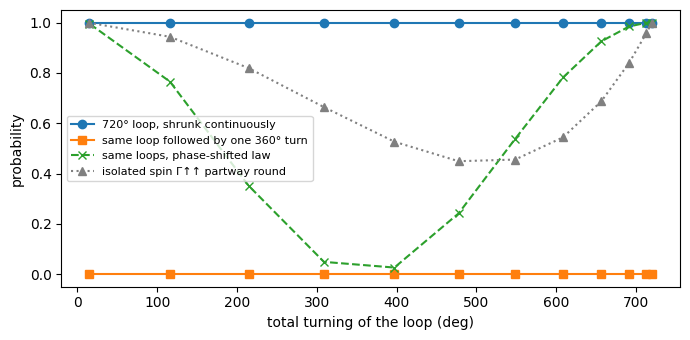

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(turning, pO_even, 'o-', label='720° loop, shrunk continuously')
ax.plot(turning, pO_odd, 's-', label='same loop followed by one 360° turn')
ax.plot(turning, pO_shift, 'x--', label='same loops, phase-shifted law')
ax.plot(turning, iso_mid, '^:', color='gray', label='isolated spin Γ↑↑ partway round')
ax.set_xlabel('total turning of the loop (deg)'); ax.set_ylabel('probability'); ax.set_ylim(-0.05, 1.05)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

The loops change a lot as β varies: their total turning shrinks from 720° to a few degrees, and the isolated spin's
$\Gamma$ partway round changes with them. With the determinant-1 law the end-to-end detector probability does not move: it is
exactly 1 for every loop homotopic to "no rotation" and exactly 0 for the other class. With the phase-shifted law, which
has the same isolated $\Gamma$, the detector reading wanders with the shape of the loop. The topological result needs the
physical input of section 5.

Random loops show the same two-valuedness: every closed loop of rotations applied to the spin, however irregular, gives one
of exactly two detector values.

In [11]:
rng = np.random.default_rng(11)
vals = [detector_probs(law_from_path(random_loop(rng, corners=rng.integers(2, 7))))["O"] for _ in range(40)]
vals = np.array(vals)
print(f"40 random closed loops: P(O) values within 1e-9 of 0 or 1: {np.sum(np.minimum(vals, 1 - vals) < 1e-9)}/40;"
      f"  class 'trivial' (P=1): {np.sum(vals > 0.5)},  class 'non-trivial' (P=0): {np.sum(vals < 0.5)}")

40 random closed loops: P(O) values within 1e-9 of 0 or 1: 40/40;  class 'trivial' (P=1): 27,  class 'non-trivial' (P=0): 13


**The Γ statement.** Take the end-to-end $\Gamma$ of the interferometer as a function of the rotation history $R(s)$ that the
field applies to the spin in arm A, with balanced arms and no spin-independent phase that grows with the turn. On histories
with $R(1) = R(0)$ it takes exactly two values, one for each class of $\pi_1(SO(3)) = \mathbb{Z}_2$. The isolated spin's
$\Gamma$ never sees this class, at any time. No description that divides while the particle is in the arms reproduces it:
$\Gamma_{\rm total} = \Gamma(\text{end}\leftarrow\text{mid})\,\Gamma(\text{mid}\leftarrow 0)$, and from every (arm, spin)
configuration the remaining stages send the particle to O or H with probability ½, so every loop would read ½. More
generally, $\Gamma(\text{mid}\leftarrow 0)$ has identical columns for the two input ports (the first splitter's moduli are
all equal), so whatever stochastic matrix the later stages contribute, a divided $\Gamma$ can never be the identity or the
arm swap.

That 4π neutron interferometry probes a property of the process rather than of the state has been argued in the language
of channel holonomies (Kult, Åberg and Sjöqvist, arXiv:0711.2140). Notebook 15 (Aharonov–Bohm) has the same pattern with
$\pi_1$ of a punctured plane in place of $\pi_1(SO(3))$, and notebook 18's half-integer twist on a ring is a lattice analogue.

<!-- expansion:19:recap-6 -->
### 📝 Recap: section 6

- Closed loops of rotations applied to the spin (not loops of field directions, which give Berry's phase) come in two classes, $\pi_1(SO(3)) = \mathbb{Z}_2$. A 720° turn can be shrunk to nothing (the belt trick); a 360° turn cannot.
- With determinant-1 steps a closed loop's law is $+I$ or $-I$ according to its class, so $P(O)$ is exactly 1 or 0. The table shows it unchanged as the loop shrinks from 720° to 15° of
  turning, and 40 random loops give only those two values (27 and 13).
- The lone spin's Γ partway round changes with the loop's shape and never sees the class.
- The phase-shifted law gives $P(O) = \tfrac12(1 + \cos(T/2))$, which wanders: the topological result needs section 5's physical input.
- Divided while the particle is in the arms, every loop would read ½.


## 7. What This Explains, and What It Only Relocates

- **Clarified.** "Not restored by 360°" is false of the spin's configurations and of its $\Gamma$. It is true only of the
  process *relative to an unrotated partner*, and it shows up only in an end-to-end $\Gamma$ that no divisible description
  reproduces.
- **Stated without Hilbert space.** The 4π period and the $\mathbb{Z}_2$ dependence on the rotation path are properties of an
  end-to-end $\Gamma$.
- **Derived without Hilbert space.** A rotation that moves the configurations and then comes back cannot be divisible
  (section 4, known). The divisible
  interferometer prediction is flat (section 3).
- **Not derived.** Section 5 uses a composing $\Theta$ with $\Gamma = |\Theta|^2$, and the physical input that the arm-A law has
  determinant 1 (no spin-independent phase that grows with the turn), which the isolated spin's $\Gamma$ cannot detect. This
  notebook does not derive the $\cos^2(\theta/2)$ law. For the spin's $\Gamma$ (2×2 and doubly stochastic) a unitary $\Theta$
  always exists, since every 2×2 doubly stochastic matrix is unistochastic, and Barandes's stochastic–quantum theorem shows that any finite indivisible process embeds in a
  unistochastic one after dilation (2309.03085 §4.1, eq. 69; §5.7). Neither result fixes which unitary nature uses.
- **Escape hatch.** With enough hidden configurations a model can carry an SU(2) action classically, for example a hidden
  unit quaternion. Nelson-school stochastic mechanics incorporates spin through diffusions with rotational degrees of
  freedom (Dankel 1970; Dohrn, Guerra and Ruggiero 1979). So
  the interferometer forces "an SU(2) action somewhere, or indivisibility", not indivisibility alone.

<!-- expansion:19:books-representation -->
### 📚 From the papers: what the representation results give, and what they don't

- **Paper 2 (arXiv:2309.03085), §3.5 "Unistochastic Processes", p. 17:** "All 2 × 2 doubly stochastic matrices are unistochastic", proved in footnote 8 by writing down a 2×2 unitary with entries
  $\pm\sqrt x$, $\pm\sqrt{1-x}$. So the lone spin, whose Γ is 2×2 and doubly stochastic, always has *some* unitary Θ.
- **Paper 2, §4.1, p. 18, eq. (69):** "Every indivisible stochastic process can be regarded as a subsystem of a unistochastic process." The scope is stated just before: "indivisible stochastic
  processes with finite configuration spaces (leaving the more general case to future work)".
- **Paper 3, §4.2 "Dilations", p. 28,** the only passage on spin: "If one wished to to introduce spin as a dilation-emergeable, one could merely dilate the Hilbert space to N D dimensions,
  introduce a D-dimensional representation of SO(3) for the internal Hilbert space, and then require that the dilated time-evolution operator had the appropriate form of rotation
  symmetry." (The doubled "to" is in the original.)

**What follows for this notebook.** These results guarantee that a Θ exists; none says which one nature uses. The spin passage is a conditional sketch phrased with SO(3) and does
not mention SU(2) or the double cover. That is why section 7 lists the $\cos^2(\theta/2)$ law and the determinant-1 input as "not derived".


<!-- expansion:19:recap-7 -->
### 📝 Recap: section 7, what is and isn't derived

- **Derived from Γ alone (known results):** a rotation that moves the configurations and then comes back cannot be divisible; the divided interferometer reads ½ at every angle.
- **Stated in Γ terms, computed from Θ:** the 720° period of $P(O)$ and its two-valued dependence on the class of the rotation path.
- **Inputs, not derived:** the law Θ with $\Gamma = |\Theta|^2$, and with it $\cos^2(\theta/2)$; the determinant-1 condition (no spin-independent phase in arm A that grows with the turn).
- **Escape hatch:** with enough hidden configurations a classical model can carry an SU(2) action. The interferometer forces "an SU(2) action somewhere, or indivisibility", not indivisibility alone.


### 🔭 Looking ahead

**Connections.**
- Notebook 05: interference as the indivisibility defect. Here the interference is between the two arms.
- Notebook 06: division events. Recording the arm, or dividing at the splitters, erases the 720° signal (section 3).
- Notebooks 02–03: divisibility and indivisibility. Section 4 is a concrete case of their criteria.
- Notebook 15 (Aharonov–Bohm): the same pattern with $\pi_1$ of a punctured plane in place of $\pi_1(SO(3))$. Notebook 18's half-integer twist on a ring is a lattice analogue.

**Possible extensions.**
- Spin 1 on three configurations, where SO(3) has a genuine 3-dimensional representation. The determinant-1 law $e^{-i\varphi J_z/\hbar}$ then has period 360°, and the interferometer
  should show no 720° effect. A useful contrast to build.
- Whether the determinant-1 input can be motivated from inside an ISP, for example through a dilation of the kind Barandes sketches for spin (2507.21192 §4.2). That passage
  is hypothetical and uses SO(3); this notebook does not attempt it.
- Once the Dankel, Dohrn–Guerra–Ruggiero and Faris papers are on disk, check whether Nelson-school spin lives on SO(3) or SU(2), and sharpen section 7's escape hatch accordingly
  (an open item in `notes/lit-spinor-4pi-2026-11-16.md`).

**Prior work (checked 2026-11-16).** All as cited in the notebook's own Prior work list:
- Experiments and the relational sign: Rauch et al., Phys. Lett. A 54, 425 (1975); Werner et al., Phys. Rev. Lett. 35, 1053 (1975); Aharonov and Susskind, Phys. Rev. 158, 1237 (1967).
- Classical single-spin models: Kochen and Specker (1967), §6; Bell (1966).
- Indivisibility: Barandes 2302.10778 §§2.1, 3.5, 3.7; Pimenta arXiv:2505.08785; Kingman (1962); Goodman (1970); Ding and Rhee (2014).
- Representation and topology: Bargmann (1954); Schulman (1968); Kult, Åberg and Sjöqvist, arXiv:0711.2140 (4π as a channel holonomy).
- Representability: Barandes 2309.03085 §4.1. Stochastic mechanics and spin: Dankel (1970); Dohrn, Guerra and Ruggiero (1979); Faris (1982).
- Not found in the ISP literature as of November 2026: a worked Γ-level treatment of spin-½ or its 4π periodicity. The only spin passage (2507.21192 §4.2) does not discuss the double cover.

## Summary

- **An isolated spin is restored by 360° in Γ.** Turns about $z$ leave $\Gamma = I$ at every angle, and turns about any axis give
  $\Gamma$ with period $2\pi$. For the isolated spin, the sign of $\Theta$ at 360° is gauge.
- **Stern–Gerlach statistics do not need 720°.** The Kochen–Specker classical vector model reproduces $\cos^2(\theta/2)$.
- **The 720° is relational, and like all interference it needs indivisibility.** In a two-path interferometer
  $P(O) = \cos^2(\varphi/4)$, a statement about one end-to-end $\Gamma$. Dividing the process at the beam splitters gives ½ for
  every $\varphi$.
- **A rotation that moves the configurations and then comes back cannot be divisible.** Turns of at most 90° can be. Both
  are known: Barandes gives this $\Gamma$ as an indivisible process (2302.10778 §2.1, eq. 7), and Pimenta (§IV) shows that
  $\cos^2$ dynamics are divisible until $\det\Gamma$ first reaches 0, here at 90°.
- **SU(2) is the minimal composing law, given one physical input.** $\Gamma$ lives on SO(3), and a composing 2×2 law must be
  projective. The 720° period also needs the field to add no spin-independent phase that grows with the turn: a
  phase-shifted law with the same isolated $\Gamma$ has period 360°.
- **The end-to-end Γ depends only on the homotopy class of the rotation path.** On closed rotation histories (the rotation
  the field applies to the spin returns to the identity; balanced arms) it takes exactly two values (proof: the lift ends at $\pm I$), unchanged under the belt-trick deformation. The isolated spin's $\Gamma$ is
  blind to the class.
- **What ISP does not supply:** the $\cos^2(\theta/2)$ law itself and the absence of a spin-independent phase that grows
  with the turn. Those come
  from the law, as in standard quantum theory.

**Prior work.**
- *Experiments and the relational sign:* Rauch et al., Phys. Lett. A 54, 425 (1975); Werner et al., Phys. Rev. Lett. 35,
  1053 (1975); Aharonov and Susskind, Phys. Rev. 158, 1237 (1967).
- *Classical single-spin models:* Kochen and Specker, J. Math. Mech. 17, 59 (1967), §6; Bell, Rev. Mod. Phys. 38, 447 (1966).
- *Indivisibility:* interference as indivisibility and its erasure by division events, Barandes 2302.10778 §§3.5, 3.7; the
  $\cos^2\omega t$ example, ibid. §2.1, eq. 7; stochastic inverse implies permutation, ibid. §3.5 and Ding and Rhee, Missouri
  J. Math. Sci. 26, 98 (2014); two-configuration divisibility, Pimenta arXiv:2505.08785 and Kingman (1962).
- *Gauge, representation and topology:* the Schur–Hadamard gauge freedom of $\Theta$, Barandes 2302.10778 fn. 6 and
  2507.21192 §3.2; projective representations, Bargmann, Ann. Math. 59, 1 (1954); homotopy and half-integer spin, Schulman,
  Phys. Rev. 176, 1558 (1968); 4π as a channel holonomy, Kult, Åberg and Sjöqvist, arXiv:0711.2140.
- *Representability:* every finite indivisible process embeds in a unistochastic one after dilation, Barandes 2309.03085 §4.1.
- *Stochastic mechanics and spin:* Dankel, Arch. Rational Mech. Anal. 37, 192 (1970); Dohrn, Guerra and Ruggiero, LNP 106
  (1979); Faris, Found. Phys. 12, 1 (1982), on Stern–Gerlach and spin correlations.
- *ISP and spin:* the only spin passage found in the ISP literature (2507.21192 §4.2) suggests spin could be introduced by
  dilating with a representation of SO(3), and does not discuss the double cover.

No worked Γ-level treatment of spin-½ or its 4π periodicity was found in the ISP literature as of November 2026; the
individual ingredients above are all known. See `notes/lit-spinor-4pi-2026-11-16.md` for the literature checks behind this
notebook.

### 📖 In depth: the one-paragraph version

Seen through its transition matrices Γ, a lone spin-½ is restored by a 360° turn: Γ is the entrywise square of the law Θ, and squaring erases the famous minus sign. Stern–Gerlach statistics
cannot force 720° either, since a classical arrow model reproduces them. The 720° appears in a two-path interferometer, relative to an unrotated arm: there one end-to-end Γ gives
$P(O) = \cos^2(\varphi/4)$, while the same process divided at the splitters gives ½ for every angle, so the effect is interference and needs indivisibility. A rotation that moves the
configurations and then comes back cannot be divisible anyway, a known result. On closed rotation histories (the rotation the field applies to the spin returns to the identity)
the end-to-end Γ takes exactly two values, one per homotopy class of loops in SO(3), but only if the law has determinant 1, which is a fact about the coupling ($-\vec\mu\cdot\vec B$
adds no spin-independent phase that grows with the turn) that the lone spin's Γ cannot see. All the ingredients are known; the notebook
assembles them in Γ language and marks what Γ does not supply.

<!-- expansion:19:check -->
### 📝 Check your understanding

1. *Why does a lone spin's Γ come back after 360°?*
   $\Gamma = |\Theta|^2$ entry by entry, and $\Theta(360°) = -I$ squares to $I$. Only the sign differed, and squaring removes it.
2. *Why can't Stern–Gerlach data alone force 720°?*
   The Kochen–Specker arrow model reproduces $\cos^2(\theta/2)$ with ordinary rotations, which have period 360°.
3. *Where, in the interferometer, does the 360° sign become visible?*
   In $P(O) = \tfrac14\|(\Theta_A + I)\chi\|^2$, where arm A's law meets the unrotated arm's $I$. At 360°, $\Theta_A = -I$ cancels it and $P(O) = 0$.
4. *What does dividing the process at the splitters do, and why?*
   Each stage contributes its own Γ. The splitter's Γ is all ½, so $P(O) = \tfrac12$ for every φ: the cross terms that carry φ are gone.
5. *Can a turn of the spin be divisible?*
   Up to 90°, yes (flip rate $\tfrac12\tan\theta$). A turn that moves ↑ into ↓ and comes back, no: a divisible family that returns to $I$ consists of permutations, so it never moved.
6. *Θ and $e^{i\varphi/2}\Theta$ give the lone spin the same Γ. Why does the notebook use Θ?*
   Physics: $-\vec\mu\cdot\vec B$ is traceless, so the law has determinant 1. The other law needs a spin-independent energy shift in arm A, a phase that grows with the turn. The interferometer can tell them apart; the lone spin's Γ cannot.
7. *Why does the end-to-end Γ take only two values on closed loops?*
   The determinant-1 law of a closed loop ends at $\pm I$, and a continuous deformation cannot jump between them. The two values are the two classes of $\pi_1(SO(3)) = \mathbb{Z}_2$.
8. *Is any of this a new result?*
   No. Every ingredient is known (Barandes, Pimenta, Kingman, Wigner and Bargmann, Schulman, Aharonov and Susskind, the 1975 neutron experiments). The notebook assembles them in Γ
   language; a worked Γ-level treatment of spin-½ was not found in the ISP literature as of November 2026.
